# 05 - Interpretasi bisnis
Menerjemahkan model menjadi keputusan: kelompok risiko, ambang persetujuan yang masuk akal secara finansial, dan alasan di balik keputusan.
Semua angka di sini dihitung di **test set**. Parameter yang dipilih dari data (batas kelompok, ambang optimal) ditentukan dari **validation set** supaya test set tetap jujur.

> **Asumsi finansial di bawah ini ilustrasi, bukan data Home Credit.** Dataset tidak memuat margin keuntungan maupun kerugian per kredit macet.
> Ubah `PROFIT_RATE` dan `LOSS_RATE` sesuai skenario, lalu lihat tabel sensitivitasnya.

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docker-compose.yml").exists())
sys.path.append(str(ROOT))

from src.data import load_model_table, prepare, split

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

model = joblib.load(ROOT / "models" / "lgbm_final.joblib")
X, y = prepare(load_model_table())
X_train, X_valid, X_test, y_train, y_valid, y_test = split(X, y)

p_valid = model.predict_proba(X_valid)[:, 1]
p_test = model.predict_proba(X_test)[:, 1]
credit_valid = X_valid["amt_credit"].fillna(0)
credit_test = X_test["amt_credit"].fillna(0)
print(len(p_valid), len(p_test), f"default rate test {y_test.mean() * 100:.2f}%")

# Asumsi ilustrasi (ubah sesuai skenario):
PROFIT_RATE = 0.10   # keuntungan bersih jika lunas, sebagai fraksi dari jumlah kredit
LOSS_RATE = 0.60     # kerugian jika gagal bayar, sebagai fraksi dari jumlah kredit

46127 46127 default rate test 8.07%


## 1. Kelompok risiko
Batas kelompok diambil dari persentil prediksi di **validation set**, lalu diterapkan ke test set.
Pembagian: 10% paling berisiko, 20% berikutnya, 40% menengah, dan 30% paling aman.

In [2]:
q30, q70, q90 = np.quantile(p_valid, [0.30, 0.70, 0.90])
labels = ["D - Rendah", "C - Sedang", "B - Tinggi", "A - Sangat tinggi"]
tier = pd.cut(p_test, bins=[-np.inf, q30, q70, q90, np.inf], labels=labels)

actions = {
    "A - Sangat tinggi": "Tolak, atau setujui hanya dengan uang muka/jaminan tinggi",
    "B - Tinggi": "Tinjau manual; batasi plafon dan tenor",
    "C - Sedang": "Setujui standar dengan pemantauan pembayaran",
    "D - Rendah": "Jalur cepat otomatis; kandidat penawaran limit lebih tinggi",
}
df_t = pd.DataFrame({"tier": tier, "y": y_test.values, "p": p_test})
tiers = (df_t.groupby("tier", observed=True)
         .agg(nasabah=("y", "size"), gagal_bayar=("y", "sum"), rata_prediksi=("p", "mean"))
         .loc[list(reversed(labels))])
tiers["default_rate_%"] = (tiers["gagal_bayar"] / tiers["nasabah"] * 100).round(2)
tiers["lift"] = (tiers["default_rate_%"] / (y_test.mean() * 100)).round(2)
tiers["porsi_nasabah_%"] = (tiers["nasabah"] / tiers["nasabah"].sum() * 100).round(1)
tiers["porsi_gagal_bayar_%"] = (tiers["gagal_bayar"] / tiers["gagal_bayar"].sum() * 100).round(1)
tiers["rata_prediksi"] = tiers["rata_prediksi"].round(3)
tiers["tindakan_usulan"] = [actions[t] for t in tiers.index]
print(f"Batas probabilitas: D <= {q30:.3f} < C <= {q70:.3f} < B <= {q90:.3f} < A")
tiers

Batas probabilitas: D <= 0.027 < C <= 0.082 < B <= 0.188 < A


,nasabah,gagal_bayar,rata_prediksi,default_rate_%,lift,porsi_nasabah_%,porsi_gagal_bayar_%,tindakan_usulan
tier,,,,,,,,
A - Sangat tinggi,4711,1444,0.306,30.65,3.80,10.2,38.8,"Tolak, atau setujui hanya dengan uang muka/jam..."
B - Tinggi,8985,1166,0.122,12.98,1.61,19.5,31.3,Tinjau manual; batasi plafon dan tenor
C - Sedang,18520,918,0.048,4.96,0.61,40.2,24.7,Setujui standar dengan pemantauan pembayaran
D - Rendah,13911,196,0.017,1.41,0.17,30.2,5.3,Jalur cepat otomatis; kandidat penawaran limit...


## 2. Ambang persetujuan berdasarkan nilai finansial
Jika menyetujui satu kredit: untung `PROFIT_RATE x kredit` bila lunas, rugi `LOSS_RATE x kredit` bila gagal bayar.
Karena probabilitas model terkalibrasi baik (lihat notebook 03), nilai harapannya positif selama

`p < PROFIT_RATE / (PROFIT_RATE + LOSS_RATE)`

Ambang teoretis ini dibandingkan dengan ambang optimal yang dicari dari validation set dan dengan "setujui semua".

In [3]:
def evaluate_policy(approved, y_true, credit, profit_rate=None, loss_rate=None):
    profit_rate = PROFIT_RATE if profit_rate is None else profit_rate
    loss_rate = LOSS_RATE if loss_rate is None else loss_rate
    approved = np.asarray(approved, dtype=bool)
    y_a, c_a = y_true.values[approved], credit.values[approved]
    gain = np.where(y_a == 0, profit_rate, -loss_rate) * c_a
    return {
        "disetujui": int(approved.sum()),
        "approval_rate_%": round(approved.mean() * 100, 1),
        "default_rate_disetujui_%": round(y_a.mean() * 100, 2) if approved.any() else np.nan,
        "profit_juta": round(gain.sum() / 1e6, 1),
    }

def profit_curve(p, y_true, credit):
    """Profit kumulatif jika menyetujui dari risiko terendah ke tertinggi."""
    order = np.argsort(p)
    gain = np.where(y_true.values[order] == 0, PROFIT_RATE, -LOSS_RATE) * credit.values[order]
    return p[order], np.arange(1, len(p) + 1) / len(p), np.cumsum(gain)

p_star = PROFIT_RATE / (PROFIT_RATE + LOSS_RATE)
ps_v, frac_v, cum_v = profit_curve(p_valid, y_valid, credit_valid)
t_opt = ps_v[int(np.argmax(cum_v))]          # dipilih dari validation set

policies = {
    "Setujui semua": np.ones(len(p_test), dtype=bool),
    f"Ambang teoretis (p < {p_star:.3f})": p_test < p_star,
    f"Ambang optimal dari valid (p <= {t_opt:.3f})": p_test <= t_opt,
}
policy_table = pd.DataFrame({name: evaluate_policy(mask, y_test, credit_test) for name, mask in policies.items()}).T
policy_table["selisih_vs_semua_juta"] = (policy_table["profit_juta"] - policy_table.loc["Setujui semua", "profit_juta"]).round(1)
policy_table

,disetujui,approval_rate_%,default_rate_disetujui_%,profit_juta,selisih_vs_semua_juta
Setujui semua,46127.0,100.0,8.07,1328.7,0.0
Ambang teoretis (p < 0.143),39061.0,84.7,4.85,1611.4,282.7
Ambang optimal dari valid (p <= 0.142),39020.0,84.6,4.85,1610.1,281.4


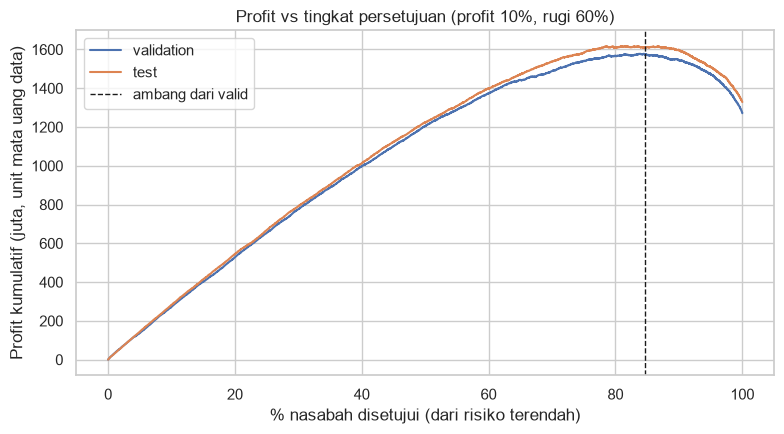

In [4]:
ps_t, frac_t, cum_t = profit_curve(p_test, y_test, credit_test)
plt.figure(figsize=(8, 4.5))
plt.plot(frac_v * 100, cum_v / 1e6, label="validation")
plt.plot(frac_t * 100, cum_t / 1e6, label="test")
plt.axvline((p_test <= t_opt).mean() * 100, color="k", linestyle="--", linewidth=1, label="ambang dari valid")
plt.xlabel("% nasabah disetujui (dari risiko terendah)")
plt.ylabel("Profit kumulatif (juta, unit mata uang data)")
plt.title(f"Profit vs tingkat persetujuan (profit {PROFIT_RATE:.0%}, rugi {LOSS_RATE:.0%})")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Sensitivitas terhadap asumsi
Seberapa besar hasilnya bergantung pada angka margin dan kerugian yang diasumsikan? Tiap baris memakai ambang teoretis `p*` untuk kombinasi itu.

In [5]:
rows = []
for pr in [0.05, 0.10, 0.20]:
    for lr in [0.40, 0.60, 0.80]:
        thr = pr / (pr + lr)
        approved = p_test < thr
        base = evaluate_policy(np.ones(len(p_test), dtype=bool), y_test, credit_test, pr, lr)
        pol = evaluate_policy(approved, y_test, credit_test, pr, lr)
        rows.append({"profit_rate": pr, "loss_rate": lr, "ambang_p*": round(thr, 3),
                     "approval_rate_%": pol["approval_rate_%"],
                     "default_rate_disetujui_%": pol["default_rate_disetujui_%"],
                     "profit_semua_juta": base["profit_juta"],
                     "profit_kebijakan_juta": pol["profit_juta"]})
sensitivity = pd.DataFrame(rows)
sensitivity

,profit_rate,loss_rate,ambang_p*,approval_rate_%,default_rate_disetujui_%,profit_semua_juta,profit_kebijakan_juta
0,0.05,0.4,0.111,78.9,4.15,460.0,716.2
1,0.05,0.6,0.077,68.5,3.32,51.3,567.9
2,0.05,0.8,0.059,59.4,2.75,-357.3,466.1
3,0.10,0.4,0.200,90.8,5.69,1737.3,1858.3
4,0.10,0.6,0.143,84.7,4.85,1328.7,1611.4
5,0.10,0.8,0.111,78.9,4.15,920.0,1432.4
6,0.20,0.4,0.333,96.9,6.99,4292.0,4328.8
7,0.20,0.6,0.250,94.0,6.31,3883.3,3995.1
8,0.20,0.8,0.200,90.8,5.69,3474.6,3716.6


## 4. Alasan di balik keputusan
Tiga nasabah berisiko tertinggi di test set, dengan tiga faktor yang paling mendorong risikonya (kontribusi dalam log-odds, dari model).
Untuk keputusan menolak, alasan seperti ini yang perlu disampaikan dan didokumentasikan.

In [6]:
top_idx = np.argsort(p_test)[-3:][::-1]
rows_top = X_test.iloc[top_idx]
contrib = model.predict(rows_top, pred_contrib=True)[:, :-1]

for rank, (i, row_c) in enumerate(zip(top_idx, contrib)):
    print(f"Nasabah {rank + 1}: prediksi gagal bayar {p_test[i] * 100:.1f}%, aktual = {int(y_test.iloc[i])}")
    for j in np.argsort(row_c)[::-1][:3]:
        print(f"   - {X_test.columns[j]} = {rows_top.iloc[rank, j]}  (kontribusi +{row_c[j]:.2f})")

Nasabah 1: prediksi gagal bayar 84.0%, aktual = 1
   - ext_source_mean = 0.018565603274492134  (kontribusi +1.04)
   - bureau_overdue_sum = 131728.5  (kontribusi +0.83)
   - ext_source_3 = 0.03711941259725027  (kontribusi +0.66)
Nasabah 2: prediksi gagal bayar 80.3%, aktual = 1
   - ext_source_mean = 0.09583628935613694  (kontribusi +0.88)
   - ext_source_2 = 0.06316820133986993  (kontribusi +0.36)
   - ext_source_3 = 0.12850437737240394  (kontribusi +0.33)
Nasabah 3: prediksi gagal bayar 79.4%, aktual = 1
   - ext_source_mean = 0.051306375324131404  (kontribusi +0.95)
   - bureau_overdue_sum = 51875.775  (kontribusi +0.71)
   - ext_source_3 = 0.0005272652387098817  (kontribusi +0.53)


## Catatan temuan
- **Kelompok risiko:** (isi dari tabel kelompok risiko: default rate, lift, dan porsi gagal bayar
  tiap kelompok A-D, serta tindakan yang diusulkan).
- **Kebijakan persetujuan:** dengan asumsi ilustrasi (untung 10%, rugi 60% dari jumlah kredit),
  menyetujui pemohon dengan p < 0,143 menyetujui 84,7% pemohon, menurunkan default rate
  disetujui dari 8,07% ke 4,85%, dan menaikkan profit sekitar 21% dibanding menyetujui semua.
- **Kalibrasi mendukung keputusan:** ambang teoretis p* = profit/(profit+rugi) = 0,143 hampir sama
  dengan ambang optimal dari validation set (0,142). Kurva profit landai di sekitar puncak,
  jadi hasil tidak sensitif terhadap pergeseran ambang kecil.
- **Sensitivitas:** kebijakan model tidak pernah lebih buruk dari "setujui semua" di 9 skenario.
  Manfaat terbesar saat margin tipis dan kerugian besar (5%/80%: setujui semua rugi, kebijakan
  model untung); manfaat terkecil saat margin tinggi (20%/40%: +0,9%).
- **Alasan keputusan:** nasabah berisiko tertinggi didorong skor eksternal sangat rendah dan,
  pada sebagian, tunggakan besar di lembaga lain (bureau_overdue_sum).
- **Keterbatasan:** angka finansial hanya ilustrasi; alasan berbasis skor eksternal kurang
  transparan bagi pemohon; kemungkinan bias seleksi karena data hanya memuat pinjaman yang
  sudah disetujui; code_gender perlu ditinjau dari sisi keadilan.